In [133]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np

# <center> Optimal Low-Rank Matrix Approximation with the SVD: Theory and Image Compression Example

## Abstract

The singular value decomposition (SVD) factorizes any matrix into two orthogonal matrices of singular vectors and a diagonal matrix of non-negative singular values, ordered from largest to smallest. Truncating this factorization gives the best low-rank approximation of the matrix in the Frobenius norm, a result known as the Eckart–Young theorem. This work presents the SVD in its full, economy and truncated forms, explains its geometric meaning, and states the Eckart–Young theorem. The theory is then illustrated with image compression: a full color photograph is converted to grayscale and approximated with several different ranks, which shows how the quality of the low-rank approximation improves as more singular values are kept. The rapid decay of the singular values and the cumulative sum show that a small number of components carries most of the image, so a moderate rank gives a good balance between compression and quality, while the remaining components add only fine detail. The work closes with other applications of the SVD and directions for further study.

## Contents

1. [Abstract](#Abstract)
2. [Introduction](#Introduction)
3. [SVD Mathematical Overview](#SVD-Mathematical-Overview)
    - [Data Matrix and Motivation](#Data-Matrix-and-Motivation)
    - [Definition of the SVD](#Definition-of-the-SVD)
    - [Geometric Interpretation](#Geometric-Interpretation)
    - [Economy SVD](#Economy-SVD)
    - [Matrix Approximation](#Matrix-Approximation)
4. [Image Compression Example](#Image-Compression-Example)
    - [Singular values](#Singular-values)
    - [Cumulative Sum of singular value](#Cumulative-Sum-of-singular-value)
5. [Applications of SVD](#Applications-of-SVD)
6. [Conclusion and next steps](#Conclusion-and-next-steps)
7. [References](#References)

## Introduction
The singular value decomposition (SVD) is a powerful matrix factorization technique in linear algebra, providing a foundation for many data methods such as Principal Component Analysis (PCA), the Dynamic Mode Decomposition (DMD), and the Proper Orthogonal Decomposition (POD). The SVD provides a numerically stable matrix decomposition that can be used for a variety of purposes and is guaranteed to exist for every matrix. Many huge datasets, such as images, ratings and text, are stored as large matrices, yet most of their information is carried by a few dominant patterns. The SVD makes these patterns explicit and ranks them by importance, which is why it is a standard first step for compression, denoising and dimensionality reduction. 
The goal of this work is to introduce the SVD and its main properties (full, economy and truncated forms) in intuitive and understanable way. Further a specific example of the compression of a grayscale image is shown and analysed.


## SVD Mathematical Overview

### Data Matrix and Motivation

Let $X \in \mathbb{R}^{n \times m}$ be a data matrix with $n$ rows and $m$ columns.

<div style="padding: 0.8em 1em; background-color: #fff4e5;">
    The SVD also exists for matrices with complex numbers, $X \in \mathbb{C}^{n \times m}$. For simplicity in this work we assume $X \in \mathbb{R}^{n \times m}$ and all examples and calculations are based on this claim. In the Data-Driven Science and Egineering book [1] the case of complex numbers is explained in detail. 
</div>

$$X = \begin{bmatrix}
x_{11} & x_{12} & \cdots & x_{1m} \\
x_{21} & x_{22} & \cdots & x_{2m} \\
\vdots & \vdots & \ddots & \vdots \\
x_{n1} & x_{n2} & \cdots & x_{nm}
\end{bmatrix}$$

The columns of $X$ are typically measurements collected from experiments or simulations, called snapshots. For instance, each column can be an image reshaped into a long vector with one entry per pixel, or the state of a physical system at one moment in time, such as the fluid velocity at a set of grid points. Putting $m$ snapshots side by side gives the matrix $X$, whose $n$ rows are the entries of each snapshot [[1]](#ref1).

Such data is high-dimensional: a single megapixel image has a million entries, and a video contains thousands of images. The SVD reduces a large data set to a small number of key features that are sufficient to describe it, which is why it is often the first step in dimensionality-reduction and machine-learning pipelines.

The SVD can also be seen as a data-driven generalization of the Fourier transform [[2]](#ref2). Both map a system into a new coordinate system in which its behavior becomes simpler, but the Fourier transform uses a fixed set of waves, while the SVD builds the coordinate system from the data itself. This is useful for systems with no ready-made transformation, such as the turbulent flow of air over an aircraft wing.

Depending on the application, the data matrix $X$ can have very different shapes. If it has many more rows than columns ($n \gg m$), it is called *tall and skinny*. If it has many more columns than rows ($n \ll m$), it is called *short and fat*.[[3]](#ref3)

<div style="padding: 0.8em 1em; background-color: #fff4e5; border-left: 4px solid #f0a030;">
In this work we select the tall and skinny matrix where $m \ll n$ and all calculations are based on this claim.
</div>

### Definition of the SVD

As it is stated in [[1]](#ref1) and [[4]](#ref4) The SVD decomposes $X$ as

$$X = U \Sigma V^\top = \begin{bmatrix} \vert & \vert & & \vert \\ u_1 & u_2 & \cdots & u_n \\ \vert & \vert & & \vert \end{bmatrix} \left[ \begin{array}{c} \begin{array}{cccc} \sigma_1 & & & \\ & \sigma_2 & & \\ & & \ddots & \\ & & & \sigma_m \end{array} \\ \hline \Large 0 \end{array} \right] \begin{bmatrix} \vert & \vert & & \vert \\ v_1 & v_2 & \cdots & v_m \\ \vert & \vert & & \vert \end{bmatrix}^\top =$$ 
$$=\begin{bmatrix} \vert & \vert & & \vert \\ u_1 & u_2 & \cdots & u_n \\ \vert & \vert & & \vert \end{bmatrix} \left[ \begin{array}{c} \begin{array}{cccc} \sigma_1 & & & \\ & \sigma_2 & & \\ & & \ddots & \\ & & & \sigma_m \end{array} \\ \hline \Large 0 \end{array} \right] \begin{bmatrix} \text{—} & v_1^\top & \text{—} \\ \text{—} & v_2^\top & \text{—} \\ & \vdots & \\ \text{—} & v_m^\top & \text{—} \end{bmatrix} \tag{1}$$

where

- $U \in \mathbb{R}^{n \times n}$ and $V \in \mathbb{R}^{m \times m}$ are **orthogonal matrices**, which means that their columns are orthonormal;
- $\Sigma \in \mathbb{R}^{n \times m}$ is a matrix with real, non-negative entries on the diagonal and zeros everywhere else.

<div style="margin: 1em 0; padding: 0.8em 1em; background-color: #e8f1fb; border-left: 4px solid #4a90d9;">
    <b>Side note: Orthogonal matrices</b><br />
First to define:<br /> 
$I$ is the identity matrix: A matrix which has ones on the diagonal and zeros everywhere else. <br />
Orthonormal vectors: A set of vectors that are both unit (with length of 1) and orthogonal (perpendicular) to each othe    
    
A real square matrix $Q$ is orthogonal when $Q^\top Q = Q Q^\top = I$, which is the same as $Q^{-1} = Q^\top$. 
Its columns (and rows) are orthonormal[[5]](#ref5)

In the SVD, $U$ and $V$ are orthogonal, so geometrically multiplying by $U$ or $V$ only rotates or reflects vectors without changing their lengths.
</div>

The following figure illustrates the matrix equation above and it is known as **Full SVD**:

![Full SVD of a tall matrix X](images/svd_full.png)

*Figure 1. Full SVD: $U$ ans $V$ are square matrices, and $\Sigma$ has the diagonal block of singular values above a block of zeros.*

So essentially $X$ is a product of three matrices where $U$ contains information of column space of $X$, $V$ contains information of the row space of $X$ and $\Sigma$ is a diagonal matrix of singular values that tells how important the various columns of $U$ and $V$ are. All theree matrices are hierachically arranged so that $u_1$ is more important than $u_2$, which is more importan than $u_3$ and so on. The same sorting is valid for $V$ and $\Sigma$ singular values.

The SVD exists for every matrix, whatever its shape. The singular values are uniquely determined by $X$, and when they are distinct the singular vectors are unique up to a sign. The proofs of these properties can be found in [[4]](#ref4). 

The columns of $U$ are called the **left singular vectors** of $X$, and the columns of $V$ are called the **right singular vectors**. The diagonal entries $\sigma_1, \dots, \sigma_m$ of $\Sigma$ are called the **singular values** of $X$. [[4]](#ref4) They are non-negative and ordered from largest to smallest:

$$\sigma_1 \ge \sigma_2 \ge \dots \ge \sigma_m \ge 0 .$$

The rank of $X$ equals the number of non-zero singular values. For real-world data, the singular values measure how much of the data is captured by each component, so the components are ordered from the most to the least important.

### Geometric Interpretation

Read from right to left, $X = U \Sigma V^\top$ acts on a vector $\mathbf{v} \in \mathbb{R}^m$ in three steps [[1]](#ref1). Here $U$ and $V$ are orthogonal matrices and $\Sigma$ is a diagonal matrix, which determines what each step does:

1. $V^\top$ is orthogonal, so it only rotates or reflects the vector without changing its length, into the coordinate system of the right singular vectors;
2. $\Sigma$ is diagonal, so it only stretches coordinate $k$ by the factor $\sigma_k$;
3. $U$ is orthogonal as well, so it only rotates or reflects the result into the output space $\mathbb{R}^n$.

So $X$ maps the unit sphere of $\mathbb{R}^m$ to an ellipsoid whose semi-axes have lengths $\sigma_k$ along the directions $u_k$. The directions with large $\sigma_k$ are where $X$ acts most strongly, which is why the leading components carry the most information.

The purpose of following example in Python is to illustrate a 2D geometric interpretation of the SVD: A matrix maps the unit circle to an ellipse: it stretches the circle along the axes by the singular values $\sigma_k$ and then rotates the result. The green and orange arrows show two unit vectors and their images, which are the semi-axes of the ellipse. In Chapter 1.3 of [[1]](#def1) a 3D Geometric illustration of the SVD is demonstrated as a mapping from a sphere to an ellipsoid.

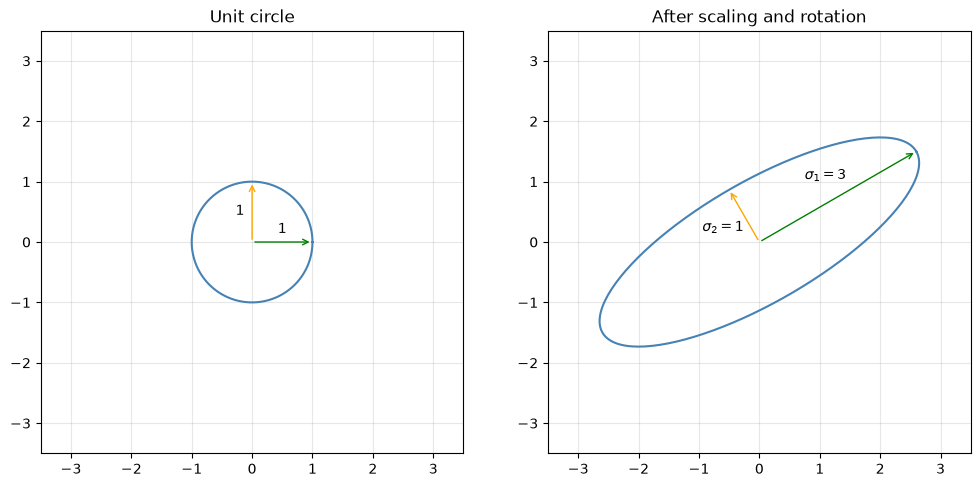

In [194]:
# Plot settings: figure size in inches (width, height) and a larger font for readability
plt.rcParams['figure.figsize'] = [12, 6]
plt.rcParams.update({'font.size': 10})

# Build the matrix X as a stretch followed by a rotation 
angle = np.pi / 6 # rotation angle in radians (30 degrees)
Sigma = np.diag([3, 1]) # stretch x by 3 and y by 1 (the Sigma singular values)

# Rotation matrix: its columns are where the unit vectors (1, 0) and (0, 1) go after rotating by the defined angle
R = np.array([[np.cos(angle), -np.sin(angle)],
              [np.sin(angle),  np.cos(angle)]])

X = R @ Sigma # first stretch, then rotate

# Points on the unit circle (one point per column) and their images under X
t = np.linspace(0, 2 * np.pi, 200)
circle = np.vstack([np.cos(t), np.sin(t)])
ellipse = X @ circle # the same points after the transformation to ellipse

# Two unit vectors along the axes (columns) and where X sends them
vecs = np.eye(2) # e_1 = (1, 0) and e_2 = (0, 1)
vecs_after = X @ vecs # X e_1 = sigma_1 u_1 and X e_2 = sigma_2 u_2 (the semi-axes of the ellipse)

arrow_colors = ['green', 'orange']

# Draw the circle on the left and the ellipse on the right
fig, (ax1, ax2) = plt.subplots(1, 2)
for ax, pts, arrows, title in [(ax1, circle, vecs, 'Unit circle'),
                               (ax2, ellipse, vecs_after, 'After scaling and rotation')]:
    ax.plot(pts[0], pts[1], color = 'steelblue')
    # arrows from the origin to the two vectors
    for k in range(2):
        ax.annotate('', xy = arrows[:, k], xytext = (0, 0), arrowprops = dict(arrowstyle = '->', color = arrow_colors[k]))
    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-3.5, 3.5)
    ax.set_aspect('equal')
    ax.grid(alpha = 0.3)
    ax.set_title(title)

# Label the semi-axes of the circle and ellipse with the singular values
sv = np.diag(Sigma)
labels = [(ax1, vecs, ['$1$', '$1$'], 0.2),
          (ax2, vecs_after, [f'$\\sigma_{k+1} = {sv[k]:g}$' for k in range(2)], 0.4)]
for ax, arrows, names, shift in labels:
    for k in range(2):
        v = arrows[:, k]                                       
        normal = np.array([-v[1], v[0]]) / np.linalg.norm(v) # unit vector perpendicular to the arrow
        ax.text(*(v / 2 + shift * normal), names[k], color = 'black', fontsize = 10, ha = 'center', va = 'center')
plt.show()

### Economy SVD 
For the $X \in \mathbb{R}^{n \times m}$, where ($m \le n$), $\Sigma$ has at most $m$ non-zero diagonal entries, so everything below its first $m$ rows is zero:

$$\Sigma = \begin{bmatrix} \hat{\Sigma} \\ 0 \end{bmatrix}, \hat{\Sigma} \in \mathbb{R}^{m \times m}.$$

Split $U$ in the same way into $U = [\hat{U} \;\; \hat{U}^\perp]$, where $\hat{U} \in \mathbb{R}^{n \times m}$ contains the first $m$ columns and $\hat{U}^\perp \in \mathbb{R}^{n \times (n-m)}$ contains the remaining $n - m$ columns. The columns of $\hat{U}^\perp$,  are multiplied only by zeros, so they do not contribute, and $X$ can be represented exactly by the smaller **Economy SVD**[[1]](#ref1):

$$X = U \Sigma V^\top = [\hat{U} \;\; \hat{U}^\perp] \begin{bmatrix} \hat{\Sigma} \\ 0 \end{bmatrix} V^\top = \hat{U} \hat{\Sigma} V^\top .$$

The following image depicts the Economy SVD:
![Economy SVD of a tall matrix X](images/svd_economy.png)

*Figure 2. Economy SVD: the zero block of $\Sigma$ and the matching columns of $U$ are dropped.*

### Matrix Approximation

The SVD is especially valuable because it provides an optimal low-rank approximation of a matrix $X$ for a specific rank $r$ where $r \lt \operatorname{rank}(X) \le \min(n, m)$. In fact, for a fixed $r$ there are infinitely many matrices of rank $r$ that approximate $X$. A rank-r approximation is obtained by keeping the leading r singular values and vectors, and discarding the rest. This is called the **truncated SVD** [[1]](#ref1). The result that the truncated SVD is the optimal low-rank approximation was first established by Erhard Schmidt, who is also known for the Gram–Schmidt process and who worked with function spaces. It was later rediscovered and formulated by Eckart and Young, and it is now usually called the **Eckart–Young theorem**[[6]](#ref6)

**Theorem (Eckart–Young):** Let $X \in \mathbb{R}^{n \times m}$ and $X = U \Sigma V^\top$

and let $r \le \operatorname{rank}(X)$. The optimal rank-$r$ approximation of $X$, in the least-squares sense, is the truncated SVD:

$$\underset{\tilde{X} \,:\, \operatorname{rank}(\tilde{X}) = r}{\operatorname{argmin}} \; \lVert X - \tilde{X} \rVert_F = \tilde{U} \tilde{\Sigma} \tilde{V}^\top .$$

Here $\tilde{U}$ and $\tilde{V}$ contain the first $r$ columns of $U$ and $V$, $\tilde{\Sigma}$ is the leading $r \times r$ block of $\Sigma$, and $\lVert \cdot \rVert_F$ is the **Frobenius norm**, $\lVert X \rVert_F = \sqrt{\sum_{i,j} a_{ij}^2}$. [[7]](#ref7)

<div style="margin: 1em 0; padding: 0.8em 1em; background-color: #e8f1fb; border-left: 4px solid #4a90d9;">
<b>Side note: Frobenius norm</b>

The Frobenius norm measures the overall size of a matrix: square every entry, add them up, and take the square root. Equivalently, it is the square root of the sum of the squared singular values, $\lVert X \rVert_F = \sqrt{\sigma_1^2 + \dots + \sigma_k^2}$ with $k = \min(n, m)$.

For the optimal approximation $\tilde{X} = \tilde{U} \tilde{\Sigma} \tilde{V}^\top$ from the theorem, the error is exactly

$$
\lVert X - \tilde{X} \rVert_F = \sqrt{\sigma_{r+1}^2 + \dots + \sigma_k^2},
$$

so the quality of a rank-$r$ approximation can be read directly from the discarded singular values, without reconstructing the image.

</div>

Following the notation of [[1]](#ref1), we denote the truncated SVD basis, and the approximation of $X$ that results from it, by
$$\tilde{X} = \tilde{U} \tilde{\Sigma} \tilde{V}^\top .$$

Because $\Sigma$ is diagonal, the rank-$r$ approximation is the sum of $r$ distinct rank-one matrices:

$$\tilde{X} = \sum_{k=1}^{r} \sigma_k u_k v_k^\top = \sigma_1 u_1 v_1^\top + \sigma_2 u_2 v_2^\top + \dots + \sigma_r u_r v_r^\top .$$

This is called the **dyadic summation**.[[1]](#ref1) For a given rank $r$, no other rank-$r$ matrix approximates $X$ better, in the least-squares sense, than the truncated SVD $\tilde{X}$. As a result, high-dimensional data can often be described well by a few dominant patterns, given by the leading columns of $\tilde{U}$ and $\tilde{V}$.

The following figure illuststrates the Truncated SVD:
![Truncated SVD of a tall matrix X](images/svd_truncated.png)

*Figure 3. Truncated SVD: only the first $r$ columns and singular values are kept, so $\tilde{X}$ approximates $X$.

## Image Compression Example
To illustrate matrix approximation a simple example with image compression is used in this section. The inspiration for the example comes from the Data-Driven Science and Enineering book referenced here [[1]](#ref1). Natural images are highly compressible, which makes them an intuitive test case. A grayscale image can be viewed as a real-valued matrix  $X \in \mathbb{R}^{n \times m}$, where $n$ is the number of pixels vertically and $m$ the number horizontally.

The following lines of code load and display the original full color image. Its size is full $n \times m \times 3$ where 3 are the RGB color channels.

shape: (3840, 2160, 3)
dtype: uint8


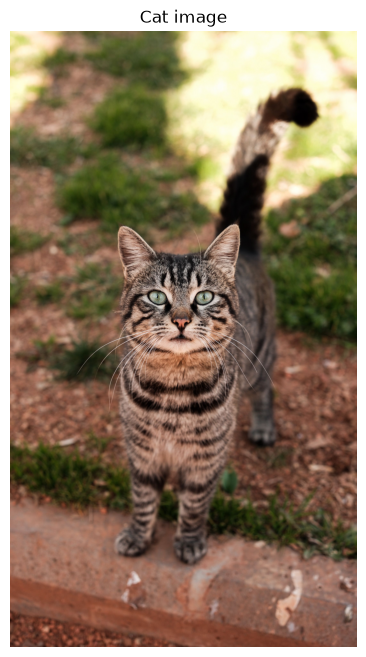

In [134]:
img = mpimg.imread("data/cat.jpg") # image read with path relative to the notebook

print("shape:", img.shape)  # (height, width, 3) for a colour image
print("dtype:", img.dtype)  # uint8 for JPEG (0-255), float32 for PNG (0-1)

plt.imshow(img)
plt.axis("off") # hide x and y axis 
plt.title("Cat image")
plt.show()

The next code converts the original SVG image into grayscale image.

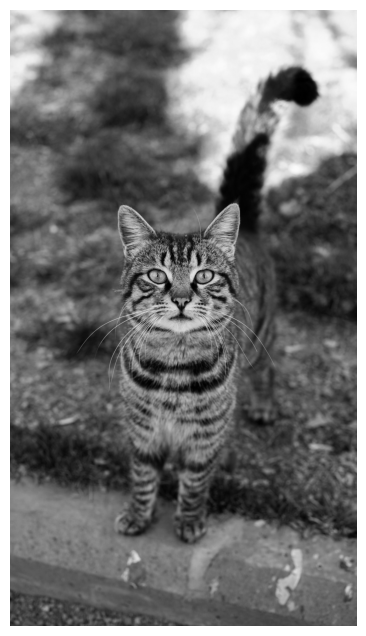

In [135]:
X = np.mean(img, -1) #convert RGB to grayscale
img = plt.imshow(X)
img.set_cmap('gray')
plt.axis('off')
plt.show()

The following code block uses the SVD implementation in Python and the goal is to experiment how the original image is compressed based on different values for the rank, how good are the achieved approximations.

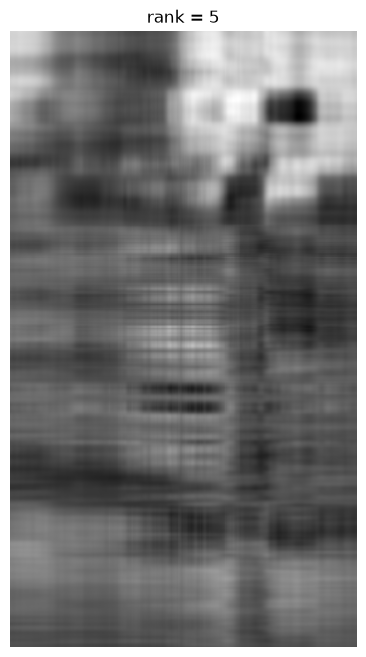

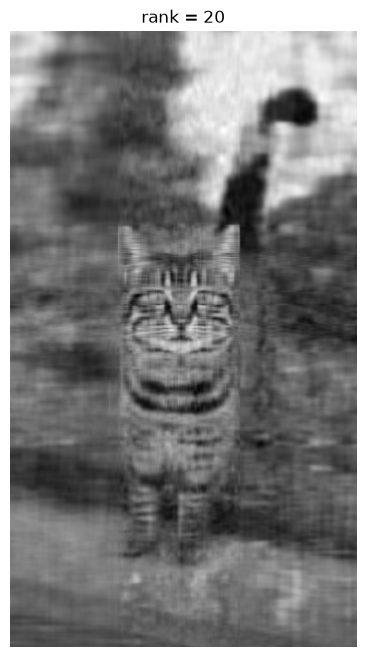

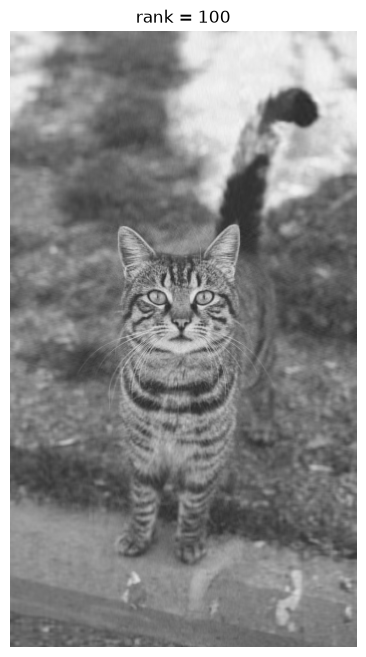

In [136]:
# Use Python implementation of SVG, full-matrices=False means that the Economy SVD is used (only the first m non-zero values of U are taken)
U, S, VT = np.linalg.svd(X,full_matrices=False) # compute SVD
S = np.diag(S) # extract the diagonal matrix S (Sigma)
j = 0
# draw the image for different rank
for r in (5, 20, 100):
    # Construct low rank approximation of the image
    # take first r columns of U; take r x r of Sigma; take first r columns of V Transposed
    Xapprox = U[:,:r] @ S[0:r,:r] @ VT[:r,:]
    plt.figure(j+1)
    j += 1
    img = plt.imshow(Xapprox)
    img.set_cmap('gray')
    plt.axis('off')
    plt.title('rank = ' + str(r))
    plt.show()

**Observations:** The image with rank 5 is quite blurry, and it is almost impossible to recognize that it shows a cat. With rank 20 it is already clear what the picture displays, but it is still blurry, since only the 20 leading singular values and vectors are used. With rank 100 the image is sharp and captures small details, while storing about 14 times fewer values than the grayscale image (see the side note below).

<div style="margin: 1em 0; padding: 0.8em 1em; background-color: #e8f1fb; border-left: 4px solid #4a90d9;">
    <b>Side note: SVD compression calculation</b>

The grayscale image has $n \times m = 3840 \times 2160 = 8{,}294{,}400$ values. The rank-$r$ approximation stores $r$ columns of $\tilde{U}$, $r$ rows of $\tilde{V}^\top$ and $r$ singular values, which is $r(n + m + 1) = 100 \times 6001 = 600{,}100$ values. The compression ratio is

$$\frac{nm}{r(n + m + 1)} = \frac{8{,}294{,}400}{600{,}100} \approx 13.8 \approx 14 .$$

Note that this counts stored values, not file size. The SVD factors are floating-point numbers that take more space than 8-bit pixels, so the actual compression of the file is smaller.
</div>

### Singular values

The following Python code plots a figure showing the singular values for the Cat image. 

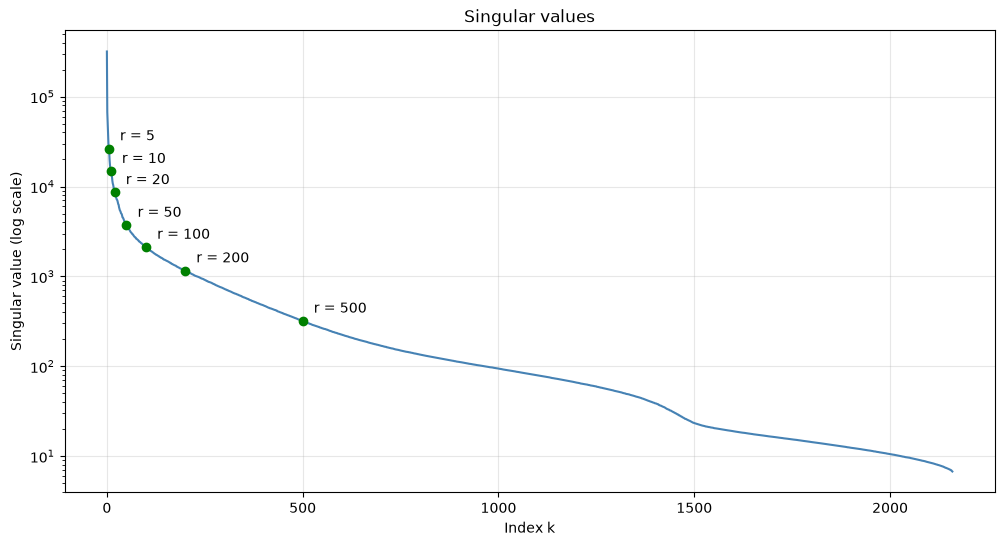

In [201]:
sv = np.diag(S) # singular values as a 1D array
ranks = [5, 10, 20, 50, 100, 200, 500]

# Plot the y-axis on a log scale, since the values span several orders of magnitude. 
# Log scales can’t show zero or negative numbers, so if some singular values are exactly 0 they won’t appear on the plot.
plt.semilogy(sv, color = 'steelblue') # log y-axis, linear x
plt.semilogy(ranks, sv[ranks], 'o', color = 'green')
for r in ranks:
    plt.annotate(f'r = {r}', (r, sv[r]), textcoords = 'offset points', xytext = (8, 6))
    
plt.xlabel('Index k')
plt.ylabel('Singular value (log scale)')
plt.title('Singular values')
plt.grid(True, alpha = 0.3)
plt.show()

**Observations:**
The figure depicts the singular values of the grayscale image on a logarithmic scale. It is noticeable that they decay rapidly: the first few components are orders of magnitude larger than the rest, they bring most valuable information and the long tail of small values corresponds to fine details. The marked points show the truncation ranks. Keeping only the $r$ largest singular values gives the best rank-$r$ approximation and the error is determined by the discarded tail. Because the tail is small beyond $r \approx 100$, a rank-100 approximation preserves most of the visible content while storing far fewer values

### Cumulative Sum of singular value

The following Python code plots the cumulative sum of the singular values that shows how much of the total sum of singular values is captured when
only the first $r$ components are kept:

$$
\frac{\sum_{k=1}^{r} \sigma_k}{\sum_{k=1}^{n} \sigma_k}
$$

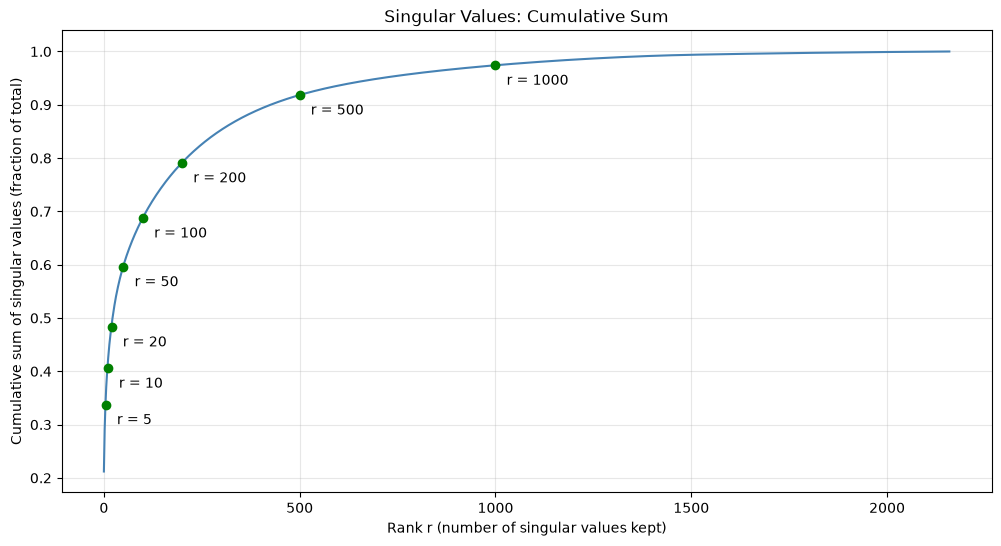

In [196]:
sv = np.diag(S) # singular values as a 1D array
cum = np.cumsum(sv) / np.sum(sv) # cumulative fraction
ranks = [5, 10, 20, 50, 100, 200, 500, 1000]

plt.plot(cum,  color = 'steelblue')
plt.plot(ranks, cum[[r - 1 for r in ranks]], 'o', color = 'green') # add dots for the ranks

for r in ranks:
    plt.annotate(f'r = {r}', (r, cum[r - 1]), textcoords = 'offset points', xytext = (8, -14))

plt.xlabel('Rank r (number of singular values kept)')
plt.ylabel('Cumulative sum of singular values (fraction of total)')
plt.title('Singular Values: Cumulative Sum')
plt.grid(True, alpha = 0.3)
plt.show()

**Observations:** The figure illustrates how the cumulative curve rises steeply at first, because the largest singular values carry most of the image structure, so even a small $r$ already captures a large fraction of the total. It then flattens, since the remaining singular values are small and add only fine detail or noise. The dots mark the ranks $r = 5, 10, 20, 50, 100, 200, 500, 1000$, and their heights show how much is retained at each truncation level. This makes it possible to choose a rank that balances compression and quality, and here $r \approx 100$ is a reasonable choice that gives pretty good results.

## Applications of SVD

The SVD is one of the most important and widely used matrix factorizations. It exists for every matrix, and it appears in mathematics, statistics, engineering and many branches of science, from numerical linear algebra to data science and machine learning [[4]](#ref4). It goes beyond the Matrix approximation and image compression that are part of this work. As we mentioned earlier it's a foundation of nearly all data methods [[1]](#ref1)(See Introduction section). Here are just some examples of the areas where the SVD plays an important role: - Data and image compression, Noise removal, Dimension reduction, Search and text mining, Recommender systems, Genomics and Weather forecasting [[4]](#ref4)[[8]](#ref8). Each of the mentiond here and in the introduction section might be a topic for research and investigation.

## Conclusion and next steps

### Conclusion
The SVD decomposes a matrix into ranked components, and by the Eckart–Young theorem the rank-$r$ truncation is the best rank-$r$ approximation in the Frobenius norm. In the image example, the rapid decay of the singular values means that a rank of $r \approx 100$ preserves most of the visible content of the image while storing far fewer values. The SVD is worth studying since it is widely used and acts as a foundation of many data science and machine learning algorithms.

### Limitations
The experiment converts a full color image of size $3840 \times 2160$ to grayscale and then compresses it using the economy SVD. In experiments with bigger images the computing time becomes noticeable. The complexity of the economy SVD is $\Theta(nm^2)$ for an $n \times m$ matrix with $m \le n$, and $\Theta(n^3)$ for a square $n \times n$ matrix, which is expensive for large matrices. In addition, the Frobenius norm measures the overall pixel error, not how good the image looks to a person, and only one image was tested, so the best rank may differ for other images.

### Future work
The analysis can be extended in several directions. Color images can be compressed by applying the SVD to each RGB channel, and for large matrices the truncated or randomized SVD can be used to compute only the leading components. The result can also be compared with JPEG or wavelet compression at equal storage. Finally, the SVD can be applied to a recommender-system or PCA problem. In the Netflix Prize scenario or with the public MovieLens dataset, a user–movie rating matrix is approximated by a low-rank factorization, and the leading components act as hidden taste factors that predict ratings a user has not given yet. This case is worth studying because most entries of such a matrix are missing, so the plain SVD cannot be applied directly, and a regularized factorization fitted only on the known ratings is used instead.

## References

<a id="ref1"></a>**[1]** Brunton, S. L., & Kutz, J. N. *Data-Driven Science and Engineering: Machine Learning, Dynamical Systems, and Control*. Cambridge University Press. <https://databookuw.com>

<a id="ref2"></a>**[2]** Wikipedia contributors. Fourier transform. *Wikipedia, The Free Encyclopedia*. <https://en.wikipedia.org/wiki/Fourier_transform>

<a id="ref3"></a>**[3]** Sargent, T. J., & Stachurski, J. Singular Value Decomposition (SVD). In *Intermediate Quantitative Economics with Python*. <https://python.quantecon.org/svd_intro.html>

<a id="ref7"></a>**[4]** Wikipedia contributors. Singular value decomposition. *Wikipedia, The Free Encyclopedia*. <https://en.wikipedia.org/wiki/Singular_value_decomposition>

<a id="ref4"></a>**[5]** Wikipedia contributors. Orthogonal matrix. *Wikipedia, The Free Encyclopedia*. <https://en.wikipedia.org/wiki/Orthogonal_matrix>

<a id="ref5"></a>**[6]** Wikipedia contributors. Low-rank approximation. *Wikipedia, The Free Encyclopedia*. <https://en.wikipedia.org/wiki/Low-rank_approximation>

<a id="ref6"></a>**[7]** Wikipedia contributors. Matrix norm. *Wikipedia, The Free Encyclopedia*. <https://en.wikipedia.org/wiki/Matrix_norm>

<a id="ref8"></a>**[8]** Jiaxing Shen (2022). Singular Value Decomposition (SVD) and Its Applications <https://shenjiaxing.win/talks/SVD%20tutorial%202022.pdf>
